Shape: (440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  \
0        2       3  12669  9656     7561     214              2674   
1        2       3   7057  9810     9568    1762              3293   
2        2       3   6353  8808     7684    2405              3516   
3        1       3  13265  1196     4221    6404               507   
4        2       3  22615  5410     7198    3915              1777   

   Delicatessen  
0          1338  
1          1776  
2          7844  
3          1788  
4          5185  

Missing values: 0

Channel:
 Channel
1    298
2    142
Name: count, dtype: int64

Region:
 Region
3    316
1     77
2     47
Name: count, dtype: int64


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.3,5796.3,7951.3,3071.9,2881.5,1524.9
std,12647.3,7380.4,9503.2,4854.7,4767.9,2820.1
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3127.8,1533.0,2153.0,742.2,256.8,408.2
50%,8504.0,3627.0,4755.5,1526.0,816.5,965.5
75%,16933.8,7190.2,10655.8,3554.2,3922.0,1820.2
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


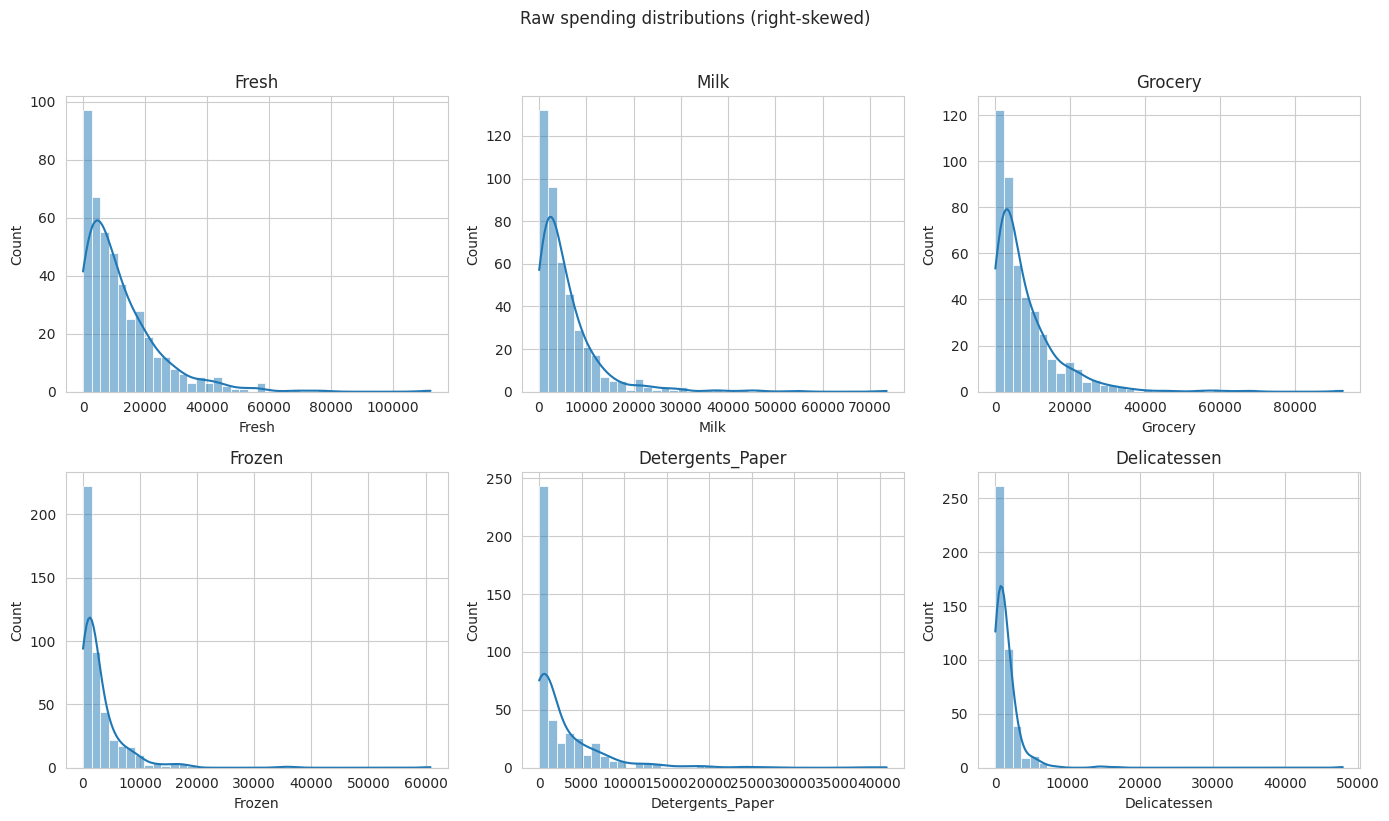

Prepared shape: (440, 6)
Means ~0: [0.0, -0.0, -0.0, 0.0, -0.0, -0.0]
Stds  ~1: [1.001, 1.001, 1.001, 1.001, 1.001, 1.001]
Hopkins statistic: 0.777  (>0.5 indicates good cluster tendency)


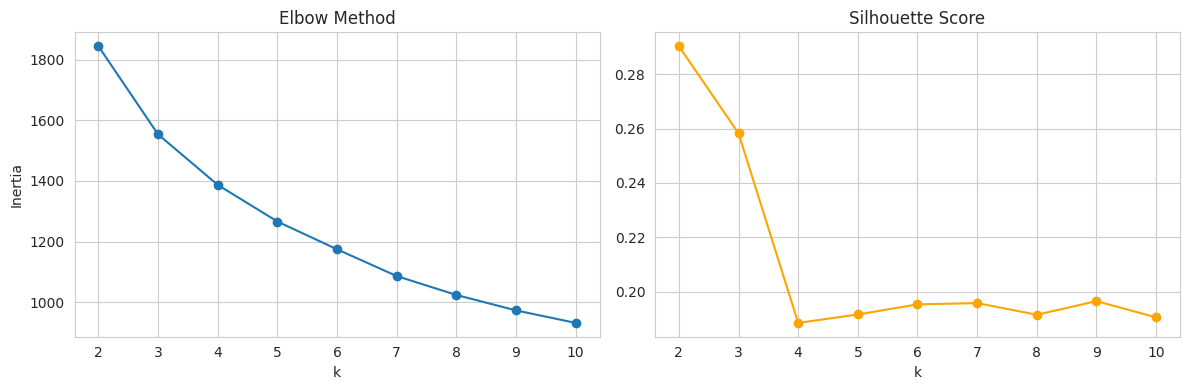

Silhouette scores: {2: np.float64(0.29), 3: np.float64(0.258), 4: np.float64(0.188), 5: np.float64(0.192), 6: np.float64(0.195), 7: np.float64(0.196), 8: np.float64(0.191), 9: np.float64(0.197), 10: np.float64(0.191)}
K-Means (k=3):
  Silhouette: 0.259
  Davies-Bouldin: 1.344
  Calinski-Harabasz: 152.9
  Cluster sizes: [ 81 212 147]


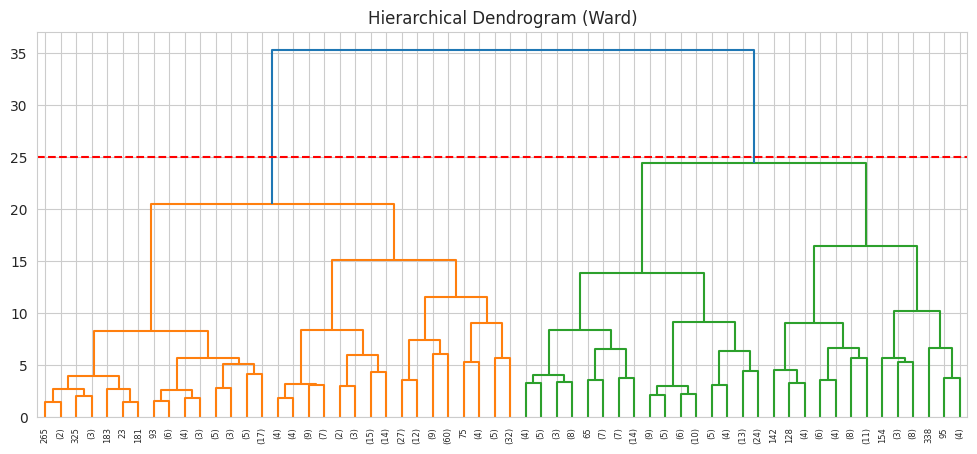

Hierarchical (Ward, k=3):
  Silhouette: 0.255
  Davies-Bouldin: 1.539
  Cluster sizes: [262  53 125]
  ARI with K-Means: 0.444


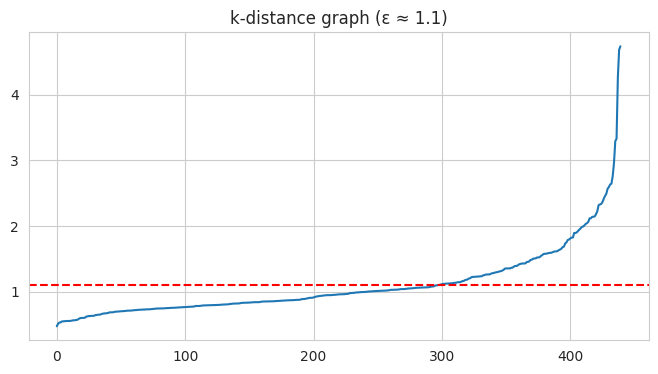

DBSCAN: 1 clusters, 96 noise points
PCA variance explained: 71.3%


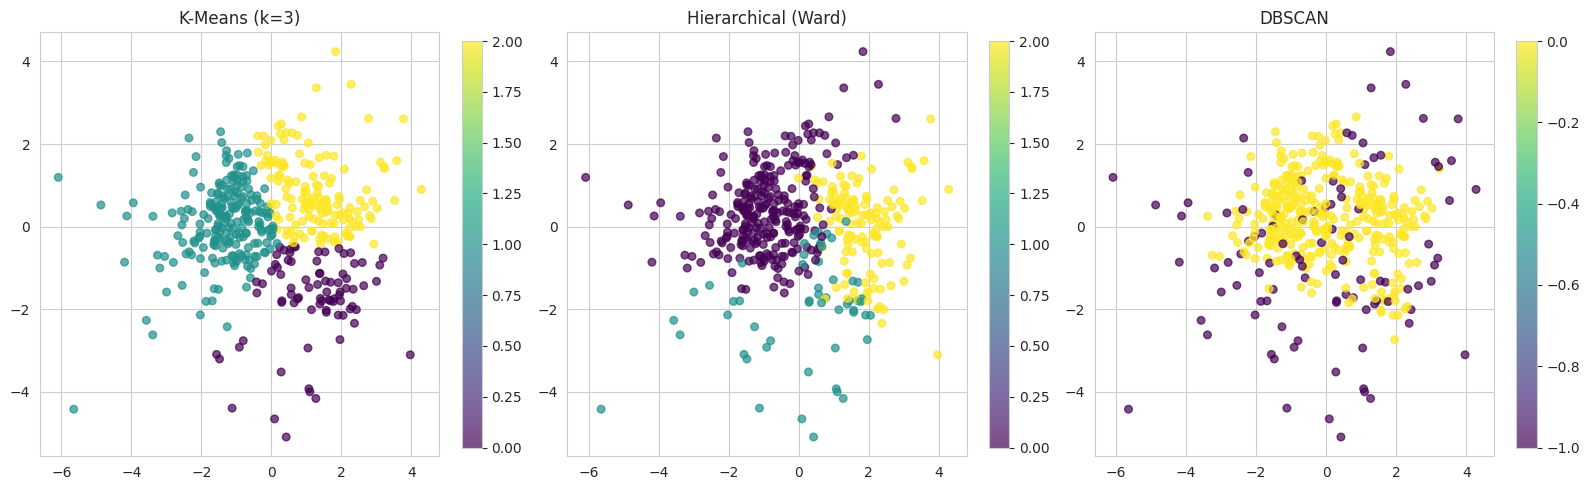

Mean spend by cluster (original units):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,2869.0,7099.0,12459.0,607.0,5487.0,781.0
1,11993.0,1995.0,2497.0,3278.0,426.0,893.0
2,17043.0,10560.0,13334.0,4133.0,4987.0,2847.0



Median spend by cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
Cluster,,,,,,
0,1454.0,6264.0,10487.0,388.0,4196.0,436.0
1,9635.0,1598.0,2151.0,2151.0,274.0,686.0
2,12126.0,7184.0,9965.0,2005.0,3378.0,2005.0



Cluster sizes: {0: 81, 1: 212, 2: 147}


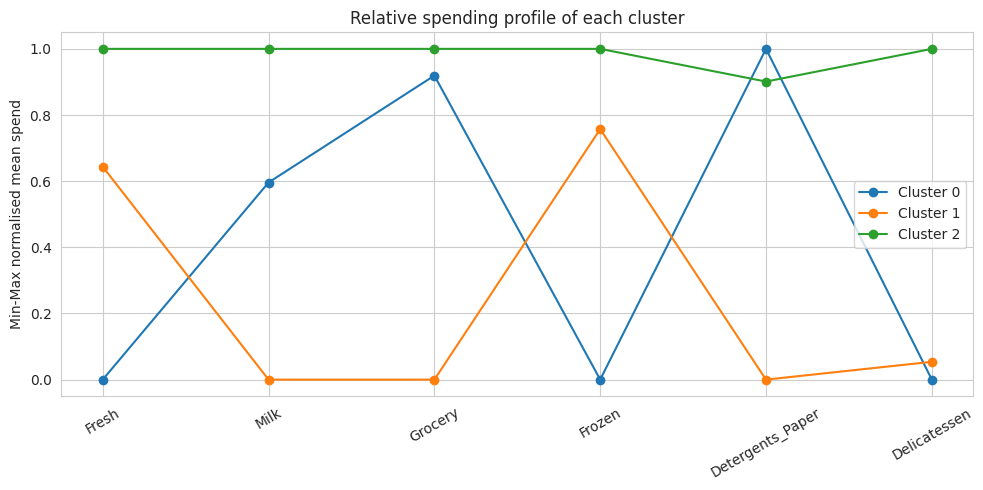


Channel distribution within clusters:


Channel,1,2
Cluster,,
0,0.41,0.59
1,0.99,0.01
2,0.38,0.62


In [1]:
# ============================================================
# PROJECT 1 – Wholesale Customers Segmentation
# DSC8307 – Data Mining, Modeling and Analytics
# ============================================================

!pip install -q scikit-learn pandas numpy matplotlib seaborn scipy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
np.random.seed(42)

# ============================================================
# 1. Load & Explore Data
# ============================================================
df = pd.read_csv('/content/wholesale-customers.csv')
print('Shape:', df.shape)
print(df.head())
print('\nMissing values:', df.isnull().sum().sum())
print('\nChannel:\n', df['Channel'].value_counts())
print('\nRegion:\n', df['Region'].value_counts())
display(df[['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicatessen']].describe().round(1))

spend_cols = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicatessen']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flatten(), spend_cols):
    sns.histplot(df[col], bins=40, kde=True, ax=ax)
    ax.set_title(col)
plt.suptitle('Raw spending distributions (right-skewed)', y=1.02)
plt.tight_layout()
plt.show()

# ============================================================
# 2. Data Preparation
# Drop Channel & Region (focus on spending behaviour only)
# Apply log1p + StandardScaler; keep outliers
# ============================================================
X_raw = df[spend_cols].copy()
X_log = np.log1p(X_raw)
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_log), columns=spend_cols)
print('Prepared shape:', X.shape)
print('Means ~0:', X.mean().round(3).tolist())
print('Stds  ~1:', X.std().round(3).tolist())

# ============================================================
# 3. Cluster Tendency (Hopkins Statistic)
# ============================================================
def hopkins_statistic(X, sample_size=None):
    from sklearn.neighbors import NearestNeighbors
    X = np.asarray(X)
    n, d = X.shape
    if sample_size is None:
        sample_size = min(int(0.1 * n), 100)
    idx = np.random.choice(n, sample_size, replace=False)
    sample = X[idx]
    mins, maxs = X.min(axis=0), X.max(axis=0)
    random_points = np.random.uniform(mins, maxs, size=(sample_size, d))
    nbrs = NearestNeighbors(n_neighbors=2).fit(X)
    u_dist, _ = nbrs.kneighbors(random_points)
    w_dist, _ = nbrs.kneighbors(sample)
    H = u_dist[:,1].sum() / (u_dist[:,1].sum() + w_dist[:,1].sum())
    return H

H = hopkins_statistic(X.values)
print(f'Hopkins statistic: {H:.3f}  (>0.5 indicates good cluster tendency)')

# ============================================================
# 4. K-Means (Partitioning)
# ============================================================
inertia, sil_scores = [], []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_range, inertia, 'o-')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[1].plot(K_range, sil_scores, 'o-', color='orange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('k')
plt.tight_layout()
plt.show()
print('Silhouette scores:', dict(zip(K_range, np.round(sil_scores, 3))))

kmeans = KMeans(n_clusters=3, random_state=42, n_init=30)
km_labels = kmeans.fit_predict(X)
print('K-Means (k=3):')
print(f'  Silhouette: {silhouette_score(X, km_labels):.3f}')
print(f'  Davies-Bouldin: {davies_bouldin_score(X, km_labels):.3f}')
print(f'  Calinski-Harabasz: {calinski_harabasz_score(X, km_labels):.1f}')
print('  Cluster sizes:', np.bincount(km_labels))

# ============================================================
# 5. Hierarchical Clustering
# ============================================================
Z = linkage(X, method='ward')
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='level', p=5)
plt.title('Hierarchical Dendrogram (Ward)')
plt.axhline(y=25, color='r', linestyle='--')
plt.show()

hier = AgglomerativeClustering(n_clusters=3, linkage='ward')
hier_labels = hier.fit_predict(X)
print('Hierarchical (Ward, k=3):')
print(f'  Silhouette: {silhouette_score(X, hier_labels):.3f}')
print(f'  Davies-Bouldin: {davies_bouldin_score(X, hier_labels):.3f}')
print('  Cluster sizes:', np.bincount(hier_labels))
print(f'  ARI with K-Means: {adjusted_rand_score(km_labels, hier_labels):.3f}')

# ============================================================
# 6. DBSCAN (Density-based)
# ============================================================
nn = NearestNeighbors(n_neighbors=5)
nn.fit(X)
distances, _ = nn.kneighbors(X)
k_dist = np.sort(distances[:, 4])
plt.figure(figsize=(8, 4))
plt.plot(k_dist)
plt.axhline(y=1.1, color='r', linestyle='--')
plt.title('k-distance graph (ε ≈ 1.1)')
plt.show()

dbscan = DBSCAN(eps=1.1, min_samples=5)
db_labels = dbscan.fit_predict(X)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)
print(f'DBSCAN: {n_clusters} clusters, {n_noise} noise points')
if n_clusters >= 2:
    mask = db_labels != -1
    print(f'  Silhouette (non-noise): {silhouette_score(X[mask], db_labels[mask]):.3f}')

# ============================================================
# 7. Visual Comparison (PCA)
# ============================================================
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print(f'PCA variance explained: {pca.explained_variance_ratio_.sum():.1%}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, labels, title in zip(axes,
                             [km_labels, hier_labels, db_labels],
                             ['K-Means (k=3)', 'Hierarchical (Ward)', 'DBSCAN']):
    sc = ax.scatter(X_pca[:,0], X_pca[:,1], c=labels, cmap='viridis', s=30, alpha=0.7)
    ax.set_title(title)
    plt.colorbar(sc, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

# ============================================================
# 8. Interpret Clusters & Recommendations
# ============================================================
df['Cluster'] = km_labels
print('Mean spend by cluster (original units):')
display(df.groupby('Cluster')[spend_cols].mean().round(0))
print('\nMedian spend by cluster:')
display(df.groupby('Cluster')[spend_cols].median().round(0))
print('\nCluster sizes:', df['Cluster'].value_counts().sort_index().to_dict())

profile = df.groupby('Cluster')[spend_cols].mean()
profile_norm = pd.DataFrame(MinMaxScaler().fit_transform(profile),
                            columns=spend_cols, index=profile.index)
plt.figure(figsize=(10, 5))
for i in profile_norm.index:
    plt.plot(spend_cols, profile_norm.loc[i], marker='o', label=f'Cluster {i}')
plt.xticks(rotation=30)
plt.ylabel('Min-Max normalised mean spend')
plt.title('Relative spending profile of each cluster')
plt.legend()
plt.tight_layout()
plt.show()

print('\nChannel distribution within clusters:')
display(pd.crosstab(df['Cluster'], df['Channel'], normalize='index').round(2))

# Cluster 0 – Fresh-focused Horeca: high Fresh & Frozen → volume discounts + frequent deliveries
# Cluster 1 – Retail / Convenience: high Milk, Grocery, Detergents → bundles + reliable delivery
# Cluster 2 – High-volume Diversified: high spend across most categories → dedicated managers + priority logistics